<a href="https://colab.research.google.com/github/danielamsouza/analise-mercado-imobiliario-pandas/blob/main/analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
url_dados = 'https://raw.githubusercontent.com/alura-cursos/pandas-conhecendo-a-biblioteca/main/base-de-dados/aluguel.csv'

In [3]:
df = pd.read_csv(url_dados, sep = ';')

In [4]:
df.head()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700.0,500.0,60.0
1,Casa,Jardim Botânico,2,0,1,100,7000.0,NaN,NaN
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200.0,4020.0,1111.0
3,Apartamento,Centro,1,0,0,15,800.0,390.0,20.0
4,Apartamento,Higienópolis,1,0,0,48,800.0,230.0,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32960 entries, 0 to 32959
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Tipo        32960 non-null  object 
 1   Bairro      32960 non-null  object 
 2   Quartos     32960 non-null  int64  
 3   Vagas       32960 non-null  int64  
 4   Suites      32960 non-null  int64  
 5   Area        32960 non-null  int64  
 6   Valor       32943 non-null  float64
 7   Condominio  28867 non-null  float64
 8   IPTU        22723 non-null  float64
dtypes: float64(3), int64(4), object(2)
memory usage: 2.3+ MB


In [6]:
df.shape

(32960, 9)

In [7]:
df.isnull().sum()

,0
Tipo,0
Bairro,0
Quartos,0
Vagas,0
Suites,0
Area,0
Valor,17
Condominio,4093
IPTU,10237


In [8]:
df = df.fillna(0).dropna(subset = ['Valor'])

In [9]:
df['Valor_Bruto'] = df['Valor'] + df['Condominio'] + df['IPTU']
df['Valor_m2'] = df['Valor'] / df['Area']

In [10]:
media_aluguel = df['Valor'].mean()

In [11]:
df['Tipo_de_Imovel'] = df['Valor'].apply(lambda x: 'Alto Padrão' if x > media_aluguel else 'Padrão')

In [12]:
df.query('Tipo == "Apartamento"')

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU,Valor_Bruto,Valor_m2,Tipo_de_Imovel
3,Apartamento,Centro,1,0,0,15,800.0,390.0,20.0,1210.0,53.333333,Padrão
4,Apartamento,Higienópolis,1,0,0,48,800.0,230.0,0.0,1030.0,16.666667,Padrão
5,Apartamento,Vista Alegre,3,1,0,70,1200.0,0.0,0.0,1200.0,17.142857,Padrão
6,Apartamento,Cachambi,2,0,0,50,1300.0,301.0,17.0,1618.0,26.000000,Padrão
10,Apartamento,Centro,1,0,0,36,1200.0,0.0,0.0,1200.0,33.333333,Padrão
...,...,...,...,...,...,...,...,...,...,...,...,...
32951,Apartamento,Vila Valqueire,2,0,0,52,1000.0,550.0,0.0,1550.0,19.230769,Padrão
32953,Apartamento,Méier,2,0,0,70,900.0,490.0,48.0,1438.0,12.857143,Padrão
32956,Apartamento,Jacarepaguá,3,1,2,78,1800.0,800.0,40.0,2640.0,23.076923,Padrão
32957,Apartamento,São Francisco Xavier,2,1,0,48,1400.0,509.0,37.0,1946.0,29.166667,Padrão


In [13]:
medias_p_bairro = df.groupby('Bairro')[['Valor', 'Condominio']].mean()

In [24]:
top_5_bairros = medias_p_bairro.sort_values(by='Valor', ascending=False).head(5)
top_5_bairros

,Valor,Condominio
Bairro,,
Jacarepaguá,314143.489637,771.860104
Irajá,154610.470588,1065.598039
Caju,120264.782609,2327.391304
Vasco da Gama,120000.000000,0.000000
Cidade Nova,88166.692308,26340.192308


<Axes: xlabel='Tipo'>

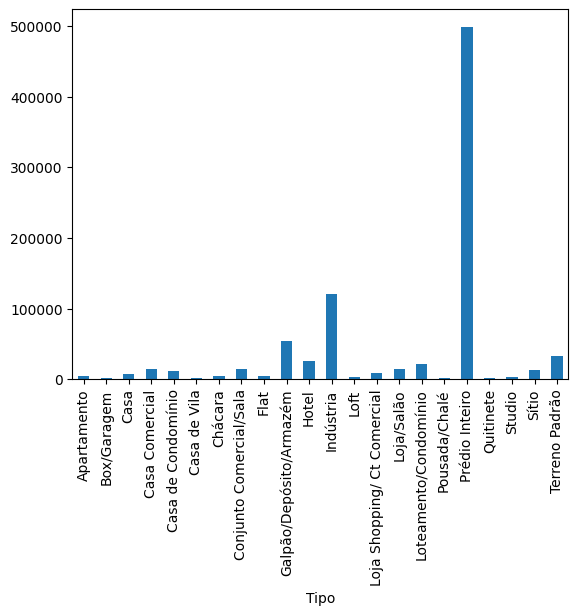

In [20]:
df.groupby('Tipo')['Valor'].mean().plot(kind= 'bar')